# BikeFlow – findings on the trip history (January 2024 – September 2026)

Analytics part of the project (Amos Mihai Andreica). The notebook reads the gold tables built by the batch layer
(`batch/09_dashboard_aggregates.py`) from the cleaned trips (`trips_clean`) and the Open-Meteo weather:

- `agg_hourly` – trips per station, month, weekday and hour
- `agg_monthly` – trips per station and month, with member and e-bike trips
- `agg_weather` – trips per day next to that day's precipitation, snowfall and temperature

It answers the questions from the proposal (section 4): demand by hour and weekday, members and e-bikes,
the trend from month to month, the busiest stations and the effect of the weather.

To run it: `pip install -r requirements-dev.txt`, then run the batch path up to `09` (or copy the gold tables into `data/lake`).

## 0. Setup

In [1]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, PercentFormatter
from deltalake import DeltaTable

LAKE = Path(os.environ.get("BIKEFLOW_DATA", "../data")) / "lake"

BLUE, ORANGE = "#2a78d6", "#eb6834"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
WEEKDAYS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
RAIN_CLASSES = ["Dry (< 1 mm)", "Wet (1–10 mm)", "Heavy rain (≥ 10 mm)"]
thousands = FuncFormatter(lambda v, _: f"{v / 1000:,.0f}k")
millions = FuncFormatter(lambda v, _: f"{v / 1e6:.0f}M")

plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984",
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": "#e4e3df", "grid.linewidth": 0.8,
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left", "legend.frameon": False,
})


def read(table, columns=None):
    return DeltaTable(str(LAKE / table)).to_pandas(columns=columns)


monthly = read("agg_monthly")
hourly = read("agg_hourly", ["weekday_num", "hour", "trips"])
weather = read("agg_weather").rename(columns={"snow_mm": "snow_cm"})
weather["date"] = pd.to_datetime(weather["date"])
weather["day_type"] = np.where(weather["weekday_num"] >= 6, "Weekend", "Weekday")

first, last = monthly["month_label"].min(), monthly["month_label"].max()
days = pd.date_range(pd.Period(first, "M").start_time, pd.Period(last, "M").end_time.normalize())
print(f"Trips: {monthly['trips'].sum():,}")
print(f"Months: {monthly['month_label'].nunique()} ({first} to {last}), days: {len(days)}")
print(f"Days with trips: {len(weather)}")
print(f"Station names in the trip files: {monthly['station_name'].nunique():,}")

Trips: 124,790,202
Months: 33 (2024-01 to 2026-09), days: 1004
Days with trips: 1003
Station names in the trip files: 2,548


Open-Meteo gives snowfall in centimetres, so the `snow_mm` column of `agg_weather` is read here as `snow_cm`.

## 1. When do people ride?

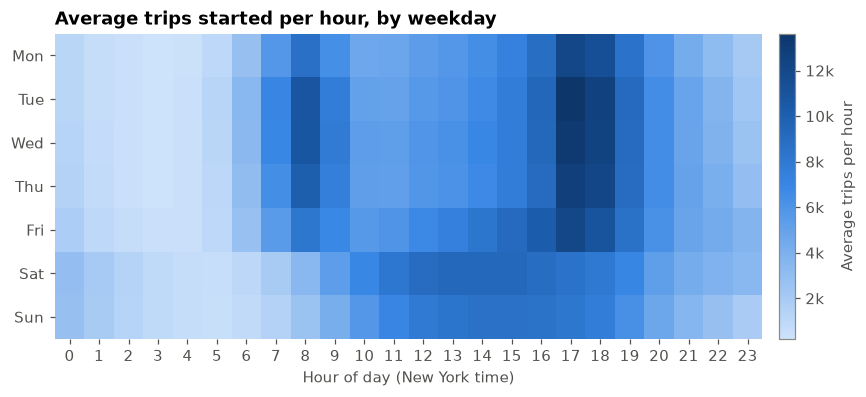

In [2]:
days_per_weekday = pd.Series(days.dayofweek + 1).value_counts().sort_index()
per_hour = hourly.groupby(["weekday_num", "hour"])["trips"].sum().unstack("hour").div(days_per_weekday, axis=0)

fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(per_hour, cmap=BLUES, aspect="auto")
ax.set_yticks(range(7), WEEKDAYS)
ax.set_xticks(range(24), range(24))
ax.set_xlabel("Hour of day (New York time)")
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
fig.colorbar(im, ax=ax, format=thousands, label="Average trips per hour", pad=0.02)
ax.set_title("Average trips started per hour, by weekday")
plt.show()

In [3]:
weekdays, weekends = per_hour.loc[1:5], per_hour.loc[6:7]
busiest = per_hour.stack().idxmax()
print(f"Busiest hour of the week: {WEEKDAYS[busiest[0] - 1]} {busiest[1]}:00, {per_hour.stack().max():,.0f} trips")
print(f"Weekdays, average per hour: 8:00 {weekdays[8].mean():,.0f}, 17:00 {weekdays[17].mean():,.0f}, 12:00 {weekdays[12].mean():,.0f}")
print(f"Weekends, busiest hour: {weekends.mean().idxmax()}:00, {weekends.mean().max():,.0f} trips")
rush = [7, 8, 16, 17, 18]
print(f"Share of weekday trips started 7:00-8:59 and 16:00-18:59: {weekdays[rush].sum().sum() / weekdays.sum().sum():.1%}")
print("Trips per hour at 0:00:", per_hour[0].rename(index=dict(enumerate(WEEKDAYS, 1))).round(0).astype(int).to_dict())
per_day = per_hour.sum(axis=1).rename(index=dict(enumerate(WEEKDAYS, 1)))
print("Trips per day:", per_day.round(-2).astype(int).to_dict())
print(f"Weekday average {per_day.iloc[:5].mean():,.0f}, weekend average {per_day.iloc[5:].mean():,.0f}")

Busiest hour of the week: Tue 17:00, 13,617 trips
Weekdays, average per hour: 8:00 9,706, 17:00 12,753, 12:00 5,879
Weekends, busiest hour: 15:00, 8,937 trips
Share of weekday trips started 7:00-8:59 and 16:00-18:59: 39.0%
Trips per hour at 0:00: {'Mon': 1150, 'Tue': 1140, 'Wed': 1310, 'Thu': 1424, 'Fri': 1781, 'Sat': 2918, 'Sun': 2766}
Trips per day: {'Mon': 117700, 'Tue': 130700, 'Wed': 132000, 'Thu': 129400, 'Fri': 132400, 'Sat': 121000, 'Sun': 106800}
Weekday average 128,456, weekend average 113,858


#### Observations – Heatmap

**Weekdays**
- Two clear peaks can be seen - the morning rush at 8:00 (about 9,700 trips per hour on average) and the evening rush at 17:00 (about 12,800), so the evening one is stronger.
- The busiest hour of the whole week is Tuesday 17:00, with about 13,600 trips.
- The five rush hours (7:00-8:59 and 16:00-18:59) hold 39% of all weekday trips - it seems most weekday trips are commutes.

**Weekends**
- There is no rush hour - trips grow slowly during the morning and stay high from about 11:00 to 18:00, with the top at 15:00 (about 8,900 trips per hour).
- Nights are busier - just after midnight on Saturday and Sunday (so Friday and Saturday night) there are about 2,800-2,900 trips per hour, about twice as many as at the same hour from Monday to Thursday (1,100-1,400).

**Per day**
- Weekdays have more trips than weekends - about 128,500 per day against 113,900.
- Sunday is the quietest day (about 106,800) and Monday is also lower than Tuesday-Friday (about 117,700 against 129,000-132,000).

## 2. Trips per month

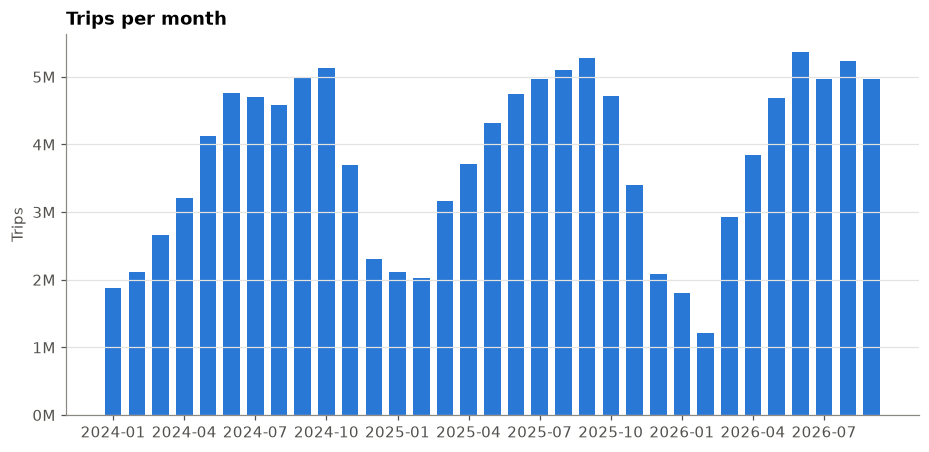

In [4]:
by_month = monthly.groupby("month_label")[["trips", "member_trips", "ebike_trips"]].sum()

fig, ax = plt.subplots()
ax.bar(by_month.index, by_month["trips"], color=BLUE, width=0.7)
ax.set_xticks(by_month.index[::3])
ax.yaxis.set_major_formatter(millions)
ax.set_ylabel("Trips")
ax.set_title("Trips per month")
plt.show()

In [5]:
year = by_month.index.str[:4]
month = by_month.index.str[5:].astype(int)
for y, trips in by_month["trips"].groupby(year):
    print(f"{y}: highest {trips.idxmax()} {trips.max():,}, lowest {trips.idxmin()} {trips.min():,}, ratio {trips.max() / trips.min():.1f}")

full_years = by_month["trips"][year < "2026"].groupby(year[year < "2026"]).sum()
print(f"\nFull years: 2024 {full_years['2024']:,}, 2025 {full_years['2025']:,} ({full_years['2025'] / full_years['2024'] - 1:+.1%})")
for label, keep in [("Jan-Sep", month <= 9), ("Mar-Sep", (month >= 3) & (month <= 9))]:
    totals = by_month["trips"][keep].groupby(year[keep]).sum()
    print(f"{label}: " + ", ".join(f"{y} {t:,}" for y, t in totals.items()),
          f"| 2025 vs 2024 {totals['2025'] / totals['2024'] - 1:+.1%}, 2026 vs 2025 {totals['2026'] / totals['2025'] - 1:+.1%}")

2024: highest 2024-10 5,132,195, lowest 2024-01 1,881,587, ratio 2.7
2025: highest 2025-09 5,271,840, lowest 2025-02 2,025,668, ratio 2.6
2026: highest 2026-06 5,366,993, lowest 2026-02 1,210,351, ratio 4.4

Full years: 2024 44,158,251, 2025 45,617,300 (+3.3%)
Jan-Sep: 2024 33,027,513, 2025 35,410,934, 2026 35,014,651 | 2025 vs 2024 +7.2%, 2026 vs 2025 -1.1%
Mar-Sep: 2024 29,030,148, 2025 31,265,780, 2026 31,997,984 | 2025 vs 2024 +7.7%, 2026 vs 2025 +2.3%


#### Observations – Trips per month

**Seasonality**
- A strong yearly cycle can be seen - few trips in winter and many from May to October. In 2024 and 2025 the best month had about 2.7 and 2.6 times the trips of the worst one.
- The peak is not in July but in early autumn - October 2024 (5.13M) and September 2025 (5.27M) were the best months of their years. In 2026 the best month so far is June (5.37M).

**Growth**
- 2025 had 3.3% more trips than 2024 (45.6M against 44.2M).
- January-September 2026 is 1.1% below the same months of 2025, but this comes from a very cold and snowy start of the year - February 2026 (1.21M) is the weakest month of the whole period. From March to September, 2026 is 2.3% above 2025.

## 3. Members and e-bikes

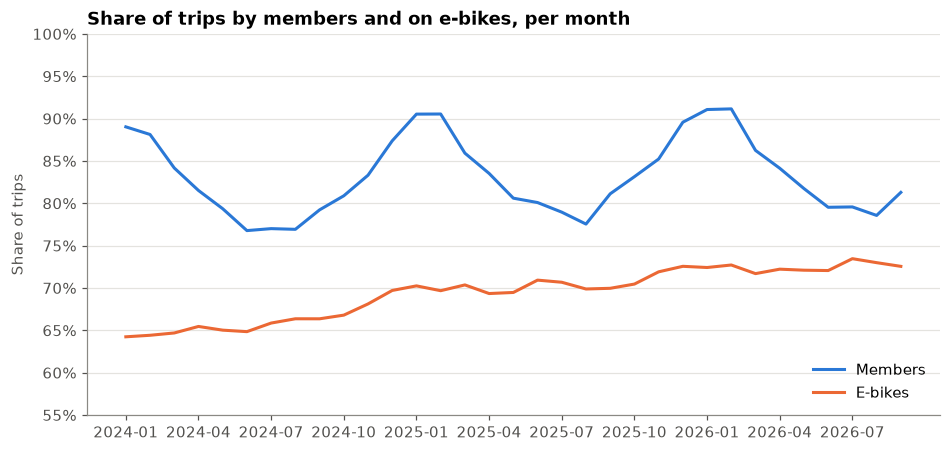

In [6]:
share = by_month[["member_trips", "ebike_trips"]].div(by_month["trips"], axis=0) * 100

fig, ax = plt.subplots()
ax.plot(share.index, share["member_trips"], color=BLUE, linewidth=2, label="Members")
ax.plot(share.index, share["ebike_trips"], color=ORANGE, linewidth=2, label="E-bikes")
ax.set_xticks(share.index[::3])
ax.set_ylim(55, 100)
ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
ax.set_ylabel("Share of trips")
ax.legend(loc="lower right")
ax.set_title("Share of trips by members and on e-bikes, per month")
plt.show()

In [7]:
total = by_month.sum()
print(f"Whole period: members {total['member_trips'] / total['trips']:.1%}, e-bikes {total['ebike_trips'] / total['trips']:.1%}")
per_year = by_month.groupby(year).sum()
print("Members per year:", (per_year["member_trips"] / per_year["trips"] * 100).round(1).to_dict())
print("E-bikes per year:", (per_year["ebike_trips"] / per_year["trips"] * 100).round(1).to_dict())
season = pd.Series(np.select([np.isin(month, [12, 1, 2]), np.isin(month, [6, 7, 8])], ["Winter (Dec-Feb)", "Summer (Jun-Aug)"], "Spring/autumn"), index=by_month.index)
per_season = by_month.groupby(season).sum()
print("Members per season:", (per_season["member_trips"] / per_season["trips"] * 100).round(1).to_dict())
print(f"Members: lowest {share['member_trips'].idxmin()} {share['member_trips'].min():.1f}%, highest {share['member_trips'].idxmax()} {share['member_trips'].max():.1f}%")
print(f"E-bikes: first month {share['ebike_trips'].iloc[0]:.1f}%, highest {share['ebike_trips'].idxmax()} {share['ebike_trips'].max():.1f}%, last month {share['ebike_trips'].iloc[-1]:.1f}%")

Whole period: members 81.8%, e-bikes 69.4%
Members per year: {'2024': 80.8, '2025': 82.6, '2026': 82.0}
E-bikes per year: {'2024': 66.0, '2025': 70.4, '2026': 72.5}
Members per season: {'Spring/autumn': 82.3, 'Summer (Jun-Aug)': 78.4, 'Winter (Dec-Feb)': 89.5}
Members: lowest 2024-06 76.8%, highest 2026-02 91.1%
E-bikes: first month 64.2%, highest 2026-07 73.5%, last month 72.6%


#### Observations – Members and e-bikes

**Members**
- Members make 81.8% of all trips.
- The share moves with the seasons - 89.5% in winter (December-February) and 78.4% in summer (June-August). It seems casual riders come mostly in the warm months, which also adds to the summer peak.

**E-bikes**
- The e-bike share grows steadily, with only small ups and downs - from 64.2% in January 2024 to 73.5% in July 2026 (66.0% in 2024, 70.4% in 2025, 72.5% in 2026 so far).
- So now almost 3 of every 4 trips are made on an e-bike.

## 4. Busiest stations

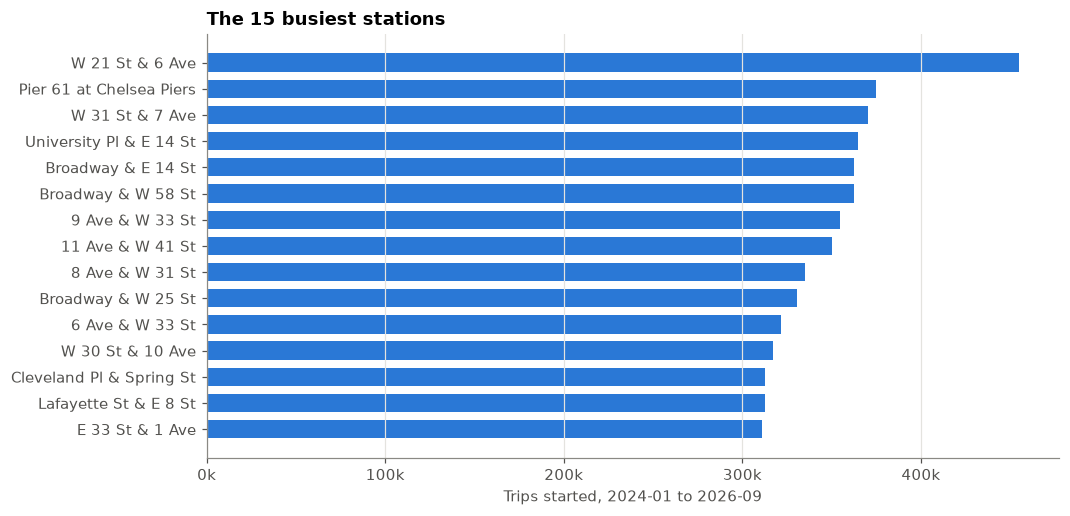

In [8]:
stations = monthly.groupby("station_name")["trips"].sum().sort_values(ascending=False)
top = stations.head(15).iloc[::-1]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top.index, top.values, color=BLUE, height=0.7)
ax.grid(False)
ax.grid(axis="x")
ax.xaxis.set_major_formatter(thousands)
ax.set_xlabel(f"Trips started, {first} to {last}")
ax.set_title("The 15 busiest stations")
plt.show()

In [9]:
print(f"Busiest: {stations.index[0]}, {stations.iloc[0]:,} trips, {stations.iloc[0] / len(days):,.0f} per day")
print(f"Top 10: {stations.head(10).sum() / stations.sum():.1%} of all trips, top 100: {stations.head(100).sum() / stations.sum():.1%}")
print(f"Median station: {stations.median():,.0f} trips ({stations.iloc[0] / stations.median():.0f} times fewer than the busiest)")
per_year = monthly.groupby(["year", "station_name"])["trips"].sum()
for y in sorted(monthly["year"].unique()):
    print(y, per_year.loc[y].nlargest(3).to_dict())

Busiest: W 21 St & 6 Ave, 454,688 trips, 453 per day
Top 10: 2.9% of all trips, top 100: 20.5%
Median station: 20,660 trips (22 times fewer than the busiest)
2024 {'W 21 St & 6 Ave': 163286, '8 Ave & W 31 St': 140399, 'University Pl & E 14 St': 139750}
2025 {'W 21 St & 6 Ave': 166539, 'Pier 61 at Chelsea Piers': 150278, 'Lafayette St & E 8 St': 146695}
2026 {'W 21 St & 6 Ave': 124863, 'Pier 61 at Chelsea Piers': 121994, '9 Ave & W 33 St': 104129}


#### Observations – Busiest stations

- W 21 St & 6 Ave is the busiest station - 454,688 trips started there, about 450 per day - and it is first in every year (2024, 2025 and 2026).
- All 15 stations are in Manhattan - several of them are around Penn Station (W 31 St & 7 Ave, 8 Ave & W 31 St, 9 Ave & W 33 St, 6 Ave & W 33 St) and around 14 St (University Pl & E 14 St, Broadway & E 14 St).
- The demand is spread over many stations - the top 10 have only 2.9% of all trips and the top 100 about 20.5% (out of 2,548 station names). A typical (median) station had about 20,700 trips, 22 times fewer than the busiest one.

## 5. Weather: rain

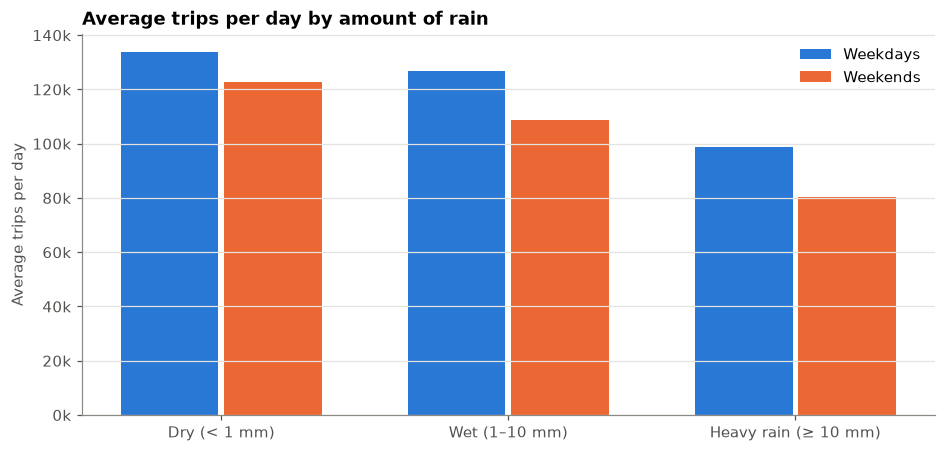

In [10]:
rain = weather.pivot_table(index="rain_category", columns="day_type", values="trips", aggfunc="mean").loc[RAIN_CLASSES]

fig, ax = plt.subplots()
x = np.arange(len(RAIN_CLASSES))
ax.bar(x - 0.18, rain["Weekday"], width=0.34, color=BLUE, label="Weekdays")
ax.bar(x + 0.18, rain["Weekend"], width=0.34, color=ORANGE, label="Weekends")
ax.set_xticks(x, RAIN_CLASSES)
ax.yaxis.set_major_formatter(thousands)
ax.set_ylabel("Average trips per day")
ax.legend()
ax.set_title("Average trips per day by amount of rain")
plt.show()

In [11]:
print("Days and average trips per day:")
print(weather.groupby("rain_category")["trips"].agg(days="count", trips_per_day="mean").loc[RAIN_CLASSES].round(0))

dry = weather[weather["rain_category"] == RAIN_CLASSES[0]].groupby(["year", "month", "day_type"])["trips"].mean().rename("dry_mean")
compared = weather.join(dry, on=["year", "month", "day_type"])
compared["change_pct"] = (compared["trips"] / compared["dry_mean"] - 1) * 100
print("\nChange against the dry days of the same month and day type (%):")
table = compared.pivot_table(index="rain_category", columns="day_type", values="change_pct", aggfunc="mean").loc[RAIN_CLASSES]
table["All days"] = compared.groupby("rain_category")["change_pct"].mean()
print(table.round(1))

Days and average trips per day:
                      days  trips_per_day
rain_category                            
Dry (< 1 mm)           652       130706.0
Wet (1–10 mm)          243       121750.0
Heavy rain (≥ 10 mm)   108        92451.0

Change against the dry days of the same month and day type (%):
day_type              Weekday  Weekend  All days
rain_category                                   
Dry (< 1 mm)             -0.0      0.0      -0.0
Wet (1–10 mm)            -8.1    -15.4     -10.2
Heavy rain (≥ 10 mm)    -30.8    -38.4     -33.4


#### Observations – Rain

- Rain lowers the number of trips, and heavy rain much more than light rain - on average 130,700 trips on dry days, 121,800 on wet days and 92,500 on heavy-rain days.
- Rainy days are not spread evenly over the year, so I also compared each day with the dry days of the same month and the same day type - with this, wet days have about 10% fewer trips and heavy-rain days about 33% fewer.
- Weekends react more than weekdays - heavy rain takes about 38% of the trips on a weekend and about 31% on a weekday. It seems commuters still have to travel, while leisure trips are easier to skip.

## 6. Weather: temperature and snow

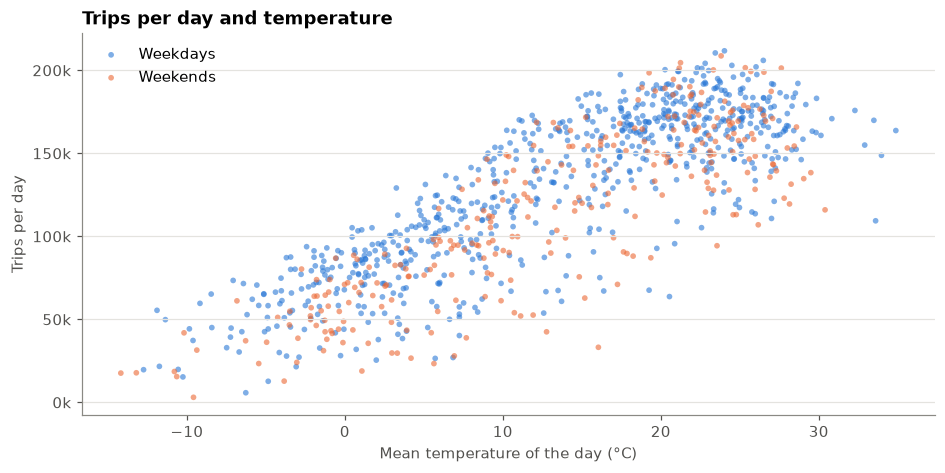

In [12]:
fig, ax = plt.subplots()
for day_type, color in [("Weekday", BLUE), ("Weekend", ORANGE)]:
    d = weather[weather["day_type"] == day_type]
    ax.scatter(d["temp_c"], d["trips"], s=14, color=color, alpha=0.6, edgecolors="none", label=f"{day_type}s")
ax.yaxis.set_major_formatter(thousands)
ax.set_xlabel("Mean temperature of the day (°C)")
ax.set_ylabel("Trips per day")
ax.legend()
ax.set_title("Trips per day and temperature")
plt.show()

In [13]:
print(f"Correlation temperature - trips: r = {weather['temp_c'].corr(weather['trips']):.2f}")
weekday_days = weather[weather["day_type"] == "Weekday"]
bands = pd.cut(weekday_days["temp_c"], [-20, 0, 5, 10, 15, 20, 25, 40])
print("\nWeekdays, average trips per day by temperature (°C):")
print(weekday_days.groupby(bands, observed=True)["trips"].agg(days="count", trips_per_day="mean").round(0))

warm_low = weather[(weather["temp_c"] >= 15) & (weather["trips"] < 120_000)]
print(f"\nWarm days (15 °C or more) with fewer than 120,000 trips: {len(warm_low)}, of them wet or heavy rain: {(warm_low['rain_category'] != RAIN_CLASSES[0]).sum()}")

print("\nDays with the fewest trips:")
print(weather.nsmallest(6, "trips")[["date", "weekday", "trips", "snow_cm", "precip_mm", "temp_c"]].to_string(index=False))
missing = days.difference(weather["date"])
print("\nDays with no trips at all:", [d.date().isoformat() for d in missing])

Correlation temperature - trips: r = 0.83

Weekdays, average trips per day by temperature (°C):
          days  trips_per_day
temp_c                       
(-20, 0]    89        59043.0
(0, 5]      92        82285.0
(5, 10]    102       102760.0
(10, 15]    72       134678.0
(15, 20]   118       155619.0
(20, 25]   151       168043.0
(25, 40]    93       166514.0

Warm days (15 °C or more) with fewer than 120,000 trips: 43, of them wet or heavy rain: 41

Days with the fewest trips:
      date  weekday  trips  snow_cm  precip_mm  temp_c
2026-01-25   Sunday   3039    19.04       33.3   -9.58
2026-01-26   Monday   5797     0.07        0.2   -6.27
2026-02-24  Tuesday  12693     0.00        0.0   -4.85
2025-12-27 Saturday  12794     3.01        4.6   -3.84
2026-01-27  Tuesday  15327     0.07        0.1  -10.25
2026-02-01   Sunday  15518     0.00        0.0  -10.64

Days with no trips at all: ['2026-02-23']


In [14]:
hourly_weather = read("weather_hourly")
storm = hourly_weather[pd.to_datetime(hourly_weather["date"]).between("2026-02-21", "2026-02-25")]
print(storm.groupby("date").agg(snow_cm=("snowfall", "sum"), precip_mm=("precipitation", "sum"),
                                temp_c=("temperature_2m", "mean"), wind_max_kmh=("wind_speed_10m", "max")).round(1))

            snow_cm  precip_mm  temp_c  wind_max_kmh
date                                                
2026-02-21      0.0        0.0     4.1          11.7
2026-02-22      9.2       15.2     1.1          26.3
2026-02-23     13.9       19.9    -0.3          33.0
2026-02-24      0.0        0.0    -4.9          17.3
2026-02-25      1.0        2.1    -0.3          14.8


#### Observations – Temperature and snow

**Temperature**
- A strong positive relationship can be seen - the correlation between the daily mean temperature and the trips is r = 0.83.
- On weekdays the average grows from about 59,000 trips at 0 °C or below to about 168,000 at 20-25 °C, and it stops growing above 25 °C (about 166,500).
- At the same temperature the number of trips still varies a lot - the low points on warm days are mostly rainy days (41 of the 43 days at 15 °C or more with fewer than 120,000 trips).

**Snow**
- The days with the fewest trips are all cold winter days - the lowest is Sunday 25 January 2026, with only 3,039 trips (19 cm of snow, -9.6 °C), followed by the next day (5,797).
- 23 February 2026 has no trips at all - it was the second day of a snowstorm (about 23 cm of snow over 22-23 February, wind up to 33 km/h). It seems the system did not run that day.

## Summary

- **Commuting shapes the weekdays** - two rush hours (8:00 and 17:00) hold 39% of weekday trips; weekends have one wide afternoon peak.
- **Strong seasons** - the best months have about 2.6-2.7 times the trips of the worst ones, with the peak in September-October.
- **Slow growth** - +3.3% from 2024 to 2025; 2026 is 2.3% above 2025 from March to September after a very cold start.
- **Members and e-bikes** - members make 81.8% of trips (89.5% in winter, 78.4% in summer); the e-bike share grew from 64% to about 73%.
- **Busiest station** - W 21 St & 6 Ave (454,688 trips, first every year), but demand is spread out - the top 100 stations hold only about 20% of trips.
- **Weather** - against dry days of the same month, heavy rain takes about a third of the trips (more on weekends); temperature has the strongest link with the number of trips (r = 0.83), and snowstorms can stop the system (23 February 2026: no trips).